# Labor Market Polarization under Differential AI Exposure
### Notebook 1: Model Architectures

**Course:** Computational Economics (A.Y. 2025-2026)  
**Institutions:** Sant'Anna School of Advanced Studies & University of Pisa  
**Professors:** Prof. G. Fagiolo, Prof. A. Roventini, Prof. A. Vandin  

**Students:** 
* Lucia D'Amore  
* Nora Donelli  
* Silvia Pagliarulo  
* Sofia Perondi  

---

### Notebook Overview
This script presents the code implementation of three nested model specifications:

1. **Model Baseline:** A baseline with equal wages and no automation.
2. **Model 1 (Poisson Automation):** A specification with differential AI exposure and Poisson adoption.
3. **Model 2 (Axelrod Social Network Extension):** A specification that adds mean-field imitation pressure to the adoption process (Bass, 1969).

All three specifications share the same population size, wage baseline, and seniority composition, so that inequality and polarization measures are directly comparable across specifications.

In [ ]:
# Import necessary libraries
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from mesa import Model, Agent
from mesa.datacollection import DataCollector

# Set matplotlib parameters for consistent styling
mpl.rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["Palatino Linotype", "Palatino", "Book Antiqua", "serif"],
    "mathtext.fontset": "stix",
    "axes.titlesize":   12,
    "axes.labelsize":   11,
    "xtick.labelsize":  10,
    "ytick.labelsize":  10,
    "figure.dpi":       110,
})

# Define constants for the simulation
SEED = 42 
N_STEPS = 150
LAMBDA_0 = 0.010097


## Baseline Model 

Under baseline conditions, the environment simulates a labor market with identical firms and fully employed workers. Each time step executes the following sequential schedule:

* **Phase 1: Firms Step (`FirmAgentBaseline`)**
  * `update_revenue()`: Since `automation_level` is fixed at `0.0`, the firm bypasses the automation logic and sets `firm_revenue` to `revenue_0` (400.0), adding it directly to its `capital`.
  * `distribute_wages()`: The firm iterates over its `employees_list`. Because revenue does not exceed `revenue_0`, the profit-sharing markup is skipped, collapsing the distributed wage to `wage_baseline` (20.0). This amount is subtracted from the firm's `capital` and transferred to each employee.

* **Phase 2: Workers Step (`WorkerAgentBaseline`)**
  * `receive_wage(wage)`: The worker splits the wage according to the `savings_rate` (0.20). A 20% fraction is added to the worker's `savings`, while the remaining 80% (consumption) is immediately added back to the `capital` of its specific `employer`, closing the monetary loop.
  * `step()`: The worker remains passive, as full employment is structurally guaranteed and no autonomous reskilling occurs in this scenario.

* **Model Development (`NetworkBoltzmannWealth`)**
  `step()`: Enforces the two-phase schedule. It first executes all `FirmAgentBaseline` instances (Phase 1), and only after completion, executes all `WorkerAgentBaseline` instances (Phase 2).
  * At the end of the step, the `DataCollector` computes the properties `calculate_gini` and `calculate_enhanced_polarization`.

### Economic Rationale
* **Closed Monetary Circuit:** Returning the consumed wage fraction directly to the employer's capital guarantees money conservation. 
* **Counterfactual Control Group:** Disabling automation ensures that all agents receive identical payments and accumulate wealth at the same rate. This maintains the global Gini coefficient at 0.0 and the polarization index at 1.0, establishing a clean counterfactual benchmark.

In [ ]:

# Baseline model: no automation, no displacement, no AI exposure. All workers earn the same wage and Gini = 0, Polarization = 1.0 for the entire simulation horizon.

class FirmAgentBaseline(Agent):
    """Firm with automation_level fixed at zero: revenue and wages never
    deviate from their initial reference values."""

    def __init__(self, model, initial_capital): # initialize firm with initial capital and automation level fixed at zero
        super().__init__(model)
        self.capital = initial_capital
        self.automation_level = 0.0
        self.employees_list = [] 
        self.firm_revenue = model.revenue_0

    # calculate firm revenue based on automation level and average skills of employees; if automation_level is 0, revenue remains at revenue_0
    # otherwise, if the automation event occurs revenues is updated based on the average skills of employees and the automation level

    def update_revenue(self):
        if self.automation_level == 1.0 and len(self.employees_list) > 0:
            media_skills = sum(w.skills for w in self.employees_list) / len(self.employees_list)
            self.firm_revenue = self.model.revenue_0 * (1 + self.automation_level * (media_skills - 1))
        else:
            self.firm_revenue = self.model.revenue_0

    # distribute wages to employees based on the profit-sharing markup formula; if firm_revenue exceeds revenue_0 (the automation event has occured), 
    # wages are increased proportionally to the excess revenue; otherwise, wages remain at the baseline level

    def distribute_wages(self):
        """Same profit-sharing markup formula used in the AI-adoption
        specifications; collapses to a flat wage here since firm_revenue
        never exceeds revenue_0."""
        w0 = self.model.wage_baseline
        revenue_0 = self.model.revenue_0
        theta = self.model.theta
        if self.firm_revenue > revenue_0:
            current_wage = w0 * (1 + theta * ((self.firm_revenue - revenue_0) / revenue_0))
        else:
            current_wage = w0
        for worker in self.employees_list:
            self.capital -= current_wage
            worker.receive_wage(current_wage)

    def step(self):
        self.update_revenue()
        self.capital += self.firm_revenue
        self.distribute_wages()


class WorkerAgentBaseline(Agent):
    """Worker labelled Junior/Senior; no AI exposure, no displacement risk."""

    def __init__(self, model, seniority, initial_savings):
        super().__init__(model)
        self.seniority = seniority
        self.savings = initial_savings
        self.skills = 1.0
        self.status = "Employed"
        self.employer = None
        self.unemployment_duration = 0

    # receive wage from employer and update savings and employer's capital accordingly; savings are calculated based on the model's savings_rate parameter
    
    def receive_wage(self, wage):
        saved = wage * self.model.savings_rate
        consumed = wage * (1 - self.model.savings_rate)
        self.savings += saved
        if self.employer:
            self.employer.capital += consumed

    def step(self):
        pass


class NetworkBoltzmannWealth(Model):
    """Bipartite labor-firm economy with equal wages and no automation.
    Serves as the null control: under correct implementation, Gini = 0
    and Polarization = 1.0 for the entire simulation horizon."""

    def __init__(self, num_firms=100, num_workers=1000, initial_firm_capital=1000.0, # initialize the model with the chosen parameters
                 initial_worker_savings=0.0, wage_baseline=20.0, savings_rate=0.20,
                 revenue_0=400.0, theta=0.35, senior_ratio=0.3, seed=None):
        super().__init__(seed=seed)
        self.wage_baseline = wage_baseline
        self.savings_rate = savings_rate
        self.revenue_0 = revenue_0
        self.theta = theta

        # Initialize the data collector to track Gini, Gini for Junior workers, and Polarization metrics at each step

        self.datacollector = DataCollector(
            model_reporters={
                "Gini": lambda m: m.calculate_gini,
                "Gini_Savings_Junior": lambda m: m.calculate_gini_savings_junior,
                "Polarization": lambda m: m.calculate_enhanced_polarization,
            }
        )

        # Create firm agents and worker agents, assigning workers to firms randomly while respecting the seniority ratio

        for _ in range(num_firms):
            FirmAgentBaseline(self, initial_firm_capital)
        firms_pool = [a for a in self.agents if isinstance(a, FirmAgentBaseline)]

        for _ in range(num_workers):
            seniority = "Senior" if self.random.random() < senior_ratio else "Junior"
            worker = WorkerAgentBaseline(self, seniority, initial_worker_savings)
            chosen_firm = self.random.choice(firms_pool)
            worker.employer = chosen_firm
            chosen_firm.employees_list.append(worker)

        self.running = True
        self.datacollector.collect(self)

    # Define the step function to execute the model in two phases: first, all firms act, then all workers react. 
    def step(self):
        """Strict two-phase scheduling execution: Firms act first, then Workers react[cite: 3]."""
        self.agents.select(agent_type=FirmAgentBaseline).shuffle_do("step")
        self.agents.select(agent_type=WorkerAgentBaseline).shuffle_do("step")
        self.datacollector.collect(self)

    # Define properties to calculate Gini coefficient, Gini for Junior workers, and Enhanced Polarization metrics based on the current state of the agents in the model.
    
    @property
    def calculate_gini(self):
        x = sorted(w.savings for w in self.agents if isinstance(w, WorkerAgentBaseline))
        n = len(x)
        if sum(x) == 0:
            return 0.0
        b = sum(xi * (n - i) for i, xi in enumerate(x)) / (n * sum(x))
        return 1 + (1 / n) - 2 * b

    @property
    def calculate_gini_savings_junior(self):
        x = sorted(w.savings for w in self.agents
                   if isinstance(w, WorkerAgentBaseline) and w.seniority == "Junior")
        n = len(x)
        if n == 0 or sum(x) == 0:
            return 0.0
        b = sum(xi * (n - i) for i, xi in enumerate(x)) / (n * sum(x))
        return 1 + (1 / n) - 2 * b

    @property
    def calculate_enhanced_polarization(self):
        workers = [w for w in self.agents if isinstance(w, WorkerAgentBaseline)]
        senior_s = [w.savings for w in workers if w.seniority == "Senior"]
        junior_s = [w.savings for w in workers if w.seniority == "Junior"]
        if not senior_s or not junior_s:
            return 1.0
        mu_j = np.mean(junior_s)
        # If the mean savings of Junior workers is zero, both cohorts hold identical null assets.
        # This implies zero relative divergence, collapsing the baseline polarization ratio to 1.0.
        return np.mean(senior_s) / mu_j if mu_j > 0 else 1.0


### Smoke test

* **Initialization:** Instantiates `NetworkBoltzmannWealth(seed=SEED)`.
* **Execution:** Runs a loop for 150 steps, calling `baseline_model.step()` at each tick.
* **Extraction:** Saves the data collector records into the DataFrame `df0`.
* **Plotting:** Generates three separate subplots via `df0.plot(subplots=True)` to visualize the trajectories.

The baseline is run for the same horizon (T = 150 periods) used in the two AI-adoption
specifications below.

c:\Users\Lucia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\mesa\mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


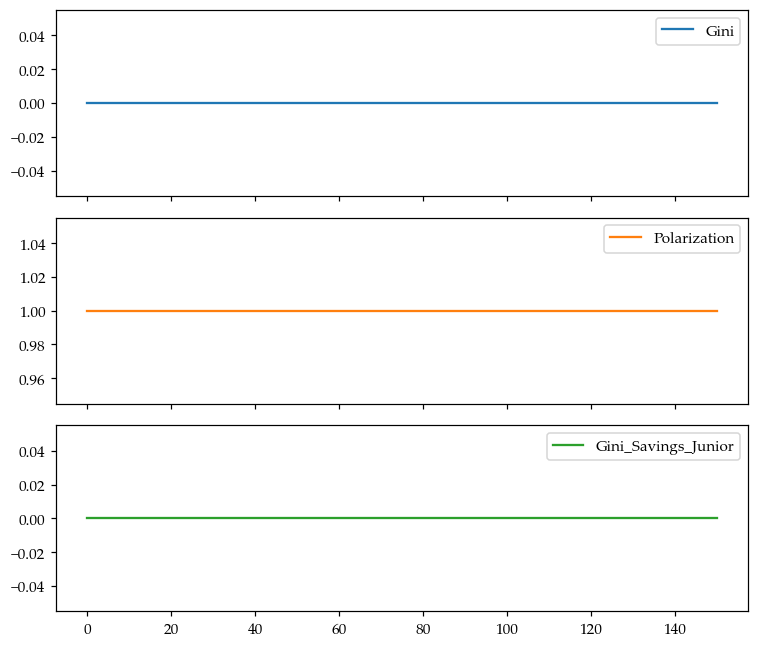

In [ ]:
# Run the baseline model for N_STEPS and collect the results
baseline_model = NetworkBoltzmannWealth(seed=SEED)
for _ in range(N_STEPS):
    baseline_model.step()

df0 = baseline_model.datacollector.get_model_vars_dataframe()
df0[["Gini", "Polarization", "Gini_Savings_Junior"]].plot(subplots=True, figsize=(7, 6))
plt.tight_layout()
plt.show()


## Extended AI-Adoption Models (Shared Core)

The two extended specifications modify the baseline by introducing technological shocks and labor market dynamics. Both models share identical agent and model code, differing only in the parameter `gamma` passed at instantiation. The core mechanisms execute as follows:

* **Differential AI Exposure:** Based on Brynjolfsson, Chandar & Chen (2025), workers face asymmetric shock exposure by seniority. Senior workers have low exposure, while Junior workers face high exposure, resulting in a higher probability of being fired.
* **Stochastic Hazard Adoption:** Based on the Bass (1969) diffusion framework, firms evaluate a Poisson hazard rate where the arrival probability is governed by $1 - e^{-(\lambda + \gamma \cdot F(t))}$, where $F(t)$ is the current adoption share. When `gamma = 0` (First Model), the hazard is purely exogenous and constant. When `gamma > 0` (Second Model), adoption accelerates endogenously through social pressure and market imitation.
* **Savings-Gated Retraining:** Displaced workers enter unemployment. Following a buffer-stock / permanent-income logic (Deaton, 1991; Carroll, 1997), a worker can only pay the retraining cost to upgrade their skills if their accumulated `savings` are above a structural threshold ($\Theta$).
* **Liquidity-Constrained Consumption:** Unemployed workers execute subsistence consumption restricted by a strict liquidity constraint: `min(subsistence_cost, max(savings, 0))`. This rule bounds consumption by current savings and prevents any implicit borrowing.

### Economic Rationale
The integration of a financial threshold ($\Theta$) for retraining and a strict floor on consumption replicates an endogenous poverty trap. Displaced workers who deplete their savings buffer below the threshold can no longer afford to reskill, becoming permanently locked out of the primary labor market. This interaction drives the long-run rise in wealth inequality (Gini) and structural polarization between cohorts.

## Model 1 Specification: Poisson Adoption
The following code block implements the unified agent and market architecture (`WorkerAgent`, `FirmAgent`, and `AutomationModel`). Under this  code state, the network intensity parameter is parameterized as `gamma = 0`, collapsing the Bass (1969) diffusion rate to a constant, exogenous hazard ($\lambda_{ai}$). This represents Model 2, where technological adoption occurs as an isolated, independent shock for each firm.

In [ ]:
# Import necessary libraries for the AI-driven displacement model
import numpy as np
from mesa import Agent, Model
from mesa.datacollection import DataCollector

# Define the WorkerAgent class
class WorkerAgent(Agent):
    """Worker labelled Junior or Senior, subject to AI-driven displacement."""

    def __init__(self, model, seniority, initial_savings):
        super().__init__(model=model)
        self.seniority = seniority
        self.savings = initial_savings
        self.skills = 1.0
        self.employed = True
        self.status = "Employed"
        self.employer = None
        self.unemployment_duration = 0
        self.did_retrain = False
        self.was_ever_displaced = False
        self.hired_without_retraining = False
        self.retraining_timer = 0
        self.last_wage = model.wage_baseline
        self.savings_rate = model.savings_rate_base
        self.hiring_weight = 1.0
        self.retraining_decision_made = False

    def receive_wage(self, wage):
        """Buffer-stock savings rule: the rate responds to wage relative to
        the economy-wide baseline (Deaton, 1991; Carroll, 1997)."""
        self.last_wage = wage

        wage_ratio = wage / self.model.wage_baseline
        raw_rate = self.model.savings_rate_base + self.model.beta_savings * (wage_ratio - 1)
        self.savings_rate = min(max(raw_rate, self.model.savings_rate_min),
                                 self.model.savings_rate_max)

        self.savings += wage * self.savings_rate
        if self.employer:
            self.employer.capital += wage * (1 - self.savings_rate)

    def step(self):
        if self.status == "Employed":
            return

        self.unemployment_duration += 1

        # Subsistence consumption, capped at available savings (no borrowing)
        consumption = min(self.model.subsistence_cost, max(self.savings, 0.0))
        self.savings -= consumption
        per_firm = consumption / len(self.model.firms_pool)
        for firm in self.model.firms_pool:
            firm.capital += per_firm

        # Retraining in progress
        # workers do retraining if they have enough savings to cover the retraining cost; the retraining process takes a fixed number of steps, 
        # after which the worker's skills increase and they have higher chances of being hired by firms; 
        if self.status == "Retraining":
            self.retraining_timer -= 1
            if self.retraining_timer <= 0:
                self.skills += self.model.skill_gain
                self.hiring_weight = self.model.retrain_signal_weight
                self.did_retrain = True
                self.status = "Unemployed"
            return

        # Retraining decision, evaluated once at first displacement
        if self.status == "Unemployed" and not self.retraining_decision_made:
            self.retraining_decision_made = True
            if self.savings >= self.model.retraining_threshold:
                self.status = "Retraining"
                self.retraining_timer = self.model.retraining_duration
                fee = self.model.training_cost
                self.savings -= fee
                per_firm_f = fee / len(self.model.firms_pool)
                for firm in self.model.firms_pool:
                    firm.capital += per_firm_f


# Define the FirmAgent class

class FirmAgent(Agent):
    """Firm with a per-firm AI-adoption hazard, learning-by-doing
    productivity, and profit-sharing markup wages."""

    def __init__(self, model, initial_capital): # initialize firm with initial capital and AI-adoption hazard, learning-by-doing productivity, and profit-sharing markup wages
        super().__init__(model=model)
        self.capital = initial_capital
        self.employees_list = []
        self.firm_revenue = model.revenue_0
        self.ai_unlocked = False
        self.already_fired = False
        self.productivity = 1.0
        self.automation_level = 0.0
        self.desired_skill = model.desired_skill
        self.patience = 0
        self.target_size = 0
        self.fired_at_step = None
        self.base_productivity = 1.0

    # AI ARRIVAL: Poisson hazard with mean-field imitation (Bass, 1969)
    # Here gamma is set to zero so we have a simple Poisson hazard for AI adoption, without any imitation effects
    def check_ai_arrival(self):
        """lambda_i(t) = lambda_0 + gamma * F(t); gamma = 0 nests the pure-Poisson case."""
        if not self.ai_unlocked:
            rate = self.model.lambda_ai + self.model.gamma * self.model.adoption_share
            p = 1 - np.exp(-rate)
            if self.random.random() < p:
                self.ai_unlocked = True

    # PRODUCTIVITY: learning-by-doing
    # productivity is updated based on the learning-by-doing formula, which increases productivity as the firm gains experience with AI adoption. 
    # The average skills of employees also influence productivity.

    def update_productivity(self):
        if self.ai_unlocked:
            self.base_productivity += self.model.rho * (self.model.pi_max - self.base_productivity)
            media_skills = (sum(w.skills for w in self.employees_list) / len(self.employees_list)
                            if self.employees_list else 1.0)
            self.productivity = self.base_productivity * media_skills

    # REVENUE 
    # revenue is updated based on the firm's productivity and fixed costs; 
    # if AI is unlocked, revenue is calculated as gross revenue minus fixed costs, ensuring it does not go below zero.

    def update_revenue(self):
        revenue_0 = self.model.revenue_0
        if self.ai_unlocked:
            gross = revenue_0 * self.productivity
            cost = self.model.ca_fixed
            self.firm_revenue = max(gross - cost, 0.0)
        else:
            self.firm_revenue = revenue_0

    # WAGES: profit-sharing markup
    # wages are distributed to employees based on the profit-sharing markup formula; if firm_revenue exceeds revenue_0 (the automation event has occured), 
    # wages are increased proportionally to the excess revenue; otherwise, wages remain at the baseline

    def distribute_wages(self):
        w0 = self.model.wage_baseline
        if self.firm_revenue > self.model.revenue_0:
            base_wage = w0 * (1 + self.model.theta *
                        (self.firm_revenue - self.model.revenue_0) / self.model.revenue_0)
        else:
            base_wage = w0

        for worker in self.employees_list:
            if worker.hired_without_retraining:
                current_wage = base_wage * self.model.underemployment_penalty
            else:
                current_wage = base_wage
            self.capital -= current_wage
            worker.receive_wage(current_wage)

    # FIRING: stochastic displacement by AI exposure (Brynjolfsson, Chandar & Chen, 2025)
    # The firing_rule method implements a stochastic displacement mechanism based on AI exposure. 
    # Each worker has a probability of being displaced based on their seniority level, with junior workers having a higher exposure risk. 
    # If a worker is displaced, they are marked as unemployed, and the firm's employee list is updated accordingly.

    def firing_rule(self):
        self.automation_level = 1.0
        for worker in list(self.employees_list):
            exposure = 0.60 if worker.seniority == "Junior" else 0.02
            if self.random.random() < exposure:
                self.model.cumulative_displaced += 1
                worker.was_ever_displaced = True
                if worker.seniority == "Junior":
                    self.model.fired_junior_step += 1
                else:
                    self.model.fired_senior_step += 1
                worker.employed = False
                worker.status = "Unemployed"
                worker.employer = None
                self.employees_list.remove(worker)

    # HIRING: signaling plus skill-based screening (Spence, 1973)
    # The evaluate_hiring method implements a hiring mechanism based on signaling and skill-based screening.
    # Firms evaluate potential candidates from the unemployed pool 
    # based on their skills and a reservation skill level determined by the firm's desired skill level and patience. 
    # If a candidate meets or exceeds the reservation skill level, they are hired; 
    # otherwise, the firm's patience increases, making it more likely to hire in future steps.

    def evaluate_hiring(self):
        if not self.ai_unlocked:
            return
        if self.capital < self.model.wage_baseline * self.model.hire_buffer:
            return
        if len(self.employees_list) >= self.target_size:
            return

        pool = self.model.get_unemployed_pool()
        if not pool:
            return

        weights = [w.hiring_weight for w in pool]
        candidate = self.random.choices(pool, weights=weights, k=1)[0]

        reservation = self.desired_skill - self.patience * self.model.patience_decay

        if candidate.skills >= reservation:
            self.hire(candidate)
            self.patience = 0
        else:
            self.patience += 1


    # Hire a worker: update the worker's employment status, skills, and the firm's employee list.

    def hire(self, worker):
        worker.employer = self
        worker.employed = True
        worker.status = "Employed"
        worker.hired_without_retraining = not worker.did_retrain
        if worker.did_retrain:
            self.model.hired_skilled_step += 1
        else:
            self.model.hired_unskilled_step += 1
        self.employees_list.append(worker)

    # STEP
    # At each step, the firm checks for AI arrival, updates productivity and revenue, distributes wages, applies the firing rule if AI is unlocked, and evaluates hiring.
    
    def step(self):
        self.check_ai_arrival()
        self.update_productivity()
        self.update_revenue()
        self.capital += self.firm_revenue
        self.distribute_wages()
        if self.ai_unlocked and not self.already_fired:
            self.firing_rule()
            self.already_fired = True
        self.evaluate_hiring()


In [ ]:

# The model with AI automation, stochastic displacement, and skill-based hiring

class AutomationModel(Model):
    def __init__(self, num_firms=100, num_workers=1000, initial_firm_capital=1000.0,    # initialize the model with the parameters chosen under calibration (calibration is described in Notebook 2)                                                                                       # d 
                 initial_worker_savings=0.0, wage_baseline=20.0, savings_rate=0.20,
                 beta_savings=0.058, savings_rate_min=0.0, savings_rate_max=0.25,
                 # beta_savings / min / max calibrated from the saving-rate-by-income-quintile
                 # range in Dynan, Skinner & Zeldes (2004)
                 revenue_0=400.0, senior_ratio=0.3, lambda_ai=0.010097,
                 gamma=0.0320,  # Bass (1969) imitation coefficient; gamma = 0 nests pure Poisson
                 rho=0.017,
                 pi_max=1.362, ca_fixed=1.22, theta=0.35, hire_buffer=3.0,
                 patience_decay=0.05, desired_skill=1.3,
                 subsistence_cost=10, training_cost=60, retrain_signal_weight=2.0,
                 buffer_months=3, seed=None):
        super().__init__(seed=seed)

        # Exogenous parameters
        self.wage_baseline = wage_baseline
        self.savings_rate_base = savings_rate
        self.beta_savings = beta_savings
        self.savings_rate_min = savings_rate_min
        self.savings_rate_max = savings_rate_max
        self.revenue_0 = revenue_0
        self.lambda_ai = lambda_ai
        self.gamma = gamma
        self.adoption_share = 0.0
        self.rho = rho
        self.pi_max = pi_max
        self.ca_fixed = ca_fixed
        self.theta = theta
        self.hire_buffer = hire_buffer
        self.patience_decay = patience_decay
        self.desired_skill = desired_skill
        self.subsistence_cost = subsistence_cost
        self.retraining_duration = 3
        self.training_cost = training_cost
        self.buffer_months = buffer_months
        self.retraining_threshold = (self.retraining_duration * self.subsistence_cost
                                      + self.training_cost
                                      + self.wage_baseline * self.buffer_months)
        self.skill_gain = 0.3
        self.underemployment_penalty = 0.85
        self.current_step = 0
        self.retrain_signal_weight = retrain_signal_weight
        self.cumulative_displaced = 0
        self.hired_skilled_step = 0
        self.hired_unskilled_step = 0
        self.fired_junior_step = 0
        self.fired_senior_step = 0

        # Data collection
        self.datacollector = DataCollector(
            model_reporters={
                "Gini": lambda m: m.calculate_gini,
                "Gini_Savings_Junior": lambda m: m.calculate_gini_savings_junior,
                "Polarization": lambda m: m.calculate_enhanced_polarization,
                "Firms_Automated": lambda m: sum(
                    1 for f in m.agents if isinstance(f, FirmAgent) and f.ai_unlocked
                ),
                "N_Unemployed": lambda m: sum(
                    1 for w in m.agents
                    if isinstance(w, WorkerAgent) and w.status == "Unemployed"
                ),
                "Mean_Productivity": lambda m: np.mean(
                    [f.productivity for f in m.agents if isinstance(f, FirmAgent)]
                ),
                "N_Reskilled_AmongDisplaced": lambda m: (
                    sum(1 for w in m.agents if isinstance(w, WorkerAgent)
                        and w.was_ever_displaced and w.did_retrain)
                    / sum(1 for w in m.agents if isinstance(w, WorkerAgent) and w.was_ever_displaced)
                    if any(isinstance(w, WorkerAgent) and w.was_ever_displaced for w in m.agents)
                    else np.nan
                ),
            }
        )

        # Create firms
        for _ in range(num_firms):
            FirmAgent(self, initial_firm_capital)
        self.firms_pool = [a for a in self.agents if isinstance(a, FirmAgent)]

        # Create workers and assign to firms (bipartite labor graph)
        for _ in range(num_workers):
            seniority = "Senior" if self.random.random() < senior_ratio else "Junior"
            worker = WorkerAgent(self, seniority, initial_worker_savings)
            firm = self.random.choice(self.firms_pool)
            worker.employer = firm
            firm.employees_list.append(worker)

        for f in self.firms_pool:
            f.target_size = len(f.employees_list)

        self.running = True
        self.datacollector.collect(self)

    # Unemployment pool 
    def get_unemployed_pool(self):
        """Workers available for hire: unemployed and not currently retraining."""
        return [
            w for w in self.agents
            if isinstance(w, WorkerAgent) and w.status == "Unemployed"
        ]

    # Metrics 
    @property
    def calculate_gini(self):
        """Gini coefficient over worker savings (0 = equality)."""
        x = sorted(w.savings for w in self.agents if isinstance(w, WorkerAgent))
        n = len(x)
        if sum(x) == 0:
            return 0.0
        b = sum(xi * (n - i) for i, xi in enumerate(x)) / (n * sum(x))
        return 1 + (1 / n) - 2 * b

    @property
    def calculate_enhanced_polarization(self):
        """Senior/Junior savings ratio; expected value 1.0 under no differential exposure."""
        workers = [w for w in self.agents if isinstance(w, WorkerAgent)]
        if not workers:
            return 1.0

        senior_s = [w.savings for w in workers if w.seniority == "Senior"]
        junior_s = [w.savings for w in workers if w.seniority == "Junior"]
        if not senior_s or not junior_s:
            return 1.0

        mu_j = np.mean(junior_s)
        return np.mean(senior_s) / mu_j if mu_j > 0 else np.nan

    @property
    def calculate_gini_savings_junior(self):
        """Gini coefficient over Junior workers' savings only (0 = equality)."""
        x = sorted(w.savings for w in self.agents if isinstance(w, WorkerAgent) and w.seniority == "Junior")
        n = len(x)
        if n == 0 or sum(x) == 0:
            return 0.0
        b = sum(xi * (n - i) for i, xi in enumerate(x)) / (n * sum(x))
        return 1 + (1 / n) - 2 * b

    # Step
    # At each step, the model updates the current step count, resets counters for hiring and firing events
    # computes the adoption share of AI among firms, 
    # and executes the step function for all firms and workers in a shuffled order. 
    # Finally, it collects data for analysis.
    
    def step(self):
        self.current_step += 1
        self.hired_skilled_step = 0
        self.hired_unskilled_step = 0
        self.fired_junior_step = 0
        self.fired_senior_step = 0
        # F(t): adoption share computed once, before firms act (synchronous mean field)
        self.adoption_share = sum(
            1 for f in self.firms_pool if f.ai_unlocked
        ) / len(self.firms_pool)
        self.agents.select(agent_type=FirmAgent).shuffle_do("step")
        self.agents.select(agent_type=WorkerAgent).shuffle_do("step")
        self.datacollector.collect(self)


### Parametric Scenario Simulation: Model 1 vs. Model 2

Rather than duplicating the codebase, we exploit the nested architecture of the `AutomationModel` class. By varying the network intensity coefficient (`gamma`), we execute both specifications sequentially over the standard horizon ($T = 150$) using an identical random seed (`SEED = 42`) to isolate the macroeconomic transmission channels of the imitation effect.

* **Model 1: Pure Poisson Process (`gamma = 0.0`)**
  * Restricts the hazard function $\lambda_i(t) = \lambda_0 + \gamma \cdot F(t)$ to the constant innovation-only adoption rate ($\lambda_0 = 0.010097$). The adoption probability of each individual firm remains statistically independent of the aggregate technological state of the market.
* **Model 2: Mean-Field Bass Diffusion (`gamma = 0.0320`)**
  * Activates the mean-field imitation term in the spirit of Axelrod's contagion dynamics, matching the Bass (1969) diffusion framework. The hazard rate scales dynamically with the aggregate market adoption share ($F(t)$), capturing industry social pressure.

Both specifications share the exact same baseline innovation rate ($\lambda_0 = 0.010097$), calibrated such that under Model 3 ($\gamma = 0.0320$), cumulative adoption reaches 46% by step 36. Holding $\lambda_0$ fixed across both runs ensures that any divergence in the shape of the adoption curves, and the resulting macroeconomic impacts, is attributable exclusively to the imitation channel.

In [ ]:
# The following code runs two instances of the AutomationModel: 
# one with no imitation effects (gamma=0.0) 
# and another with imitation effects (gamma=0.0320).

m1 = AutomationModel(seed=SEED, lambda_ai=LAMBDA_0, gamma=0.0)
for _ in range(N_STEPS):
    m1.step()
df1 = m1.datacollector.get_model_vars_dataframe()

m2 = AutomationModel(seed=SEED, lambda_ai=LAMBDA_0, gamma=0.0320)
for _ in range(N_STEPS):
    m2.step()
df2 = m2.datacollector.get_model_vars_dataframe()


c:\Users\Lucia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\mesa\mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


### AI adoption diffusion curve

The following code block plots the time series of the share of automated firms ($F(t)$) extracted from `df1` and `df2`. This chart serves to verify the empirical difference in the adoption paths generated by the two specifications:

* **Pure Poisson Specification ($\gamma = 0.0$):** Shows the baseline adoption path where the transition probability depends exclusively on the constant parameter `lambda_ai`.
* **Bass Specification ($\gamma = 0.0320$):** Shows the adoption path augmented by the interaction term `gamma * adoption_share`, displaying the acceleration in the rate of adoption as the share of automated firms increases.

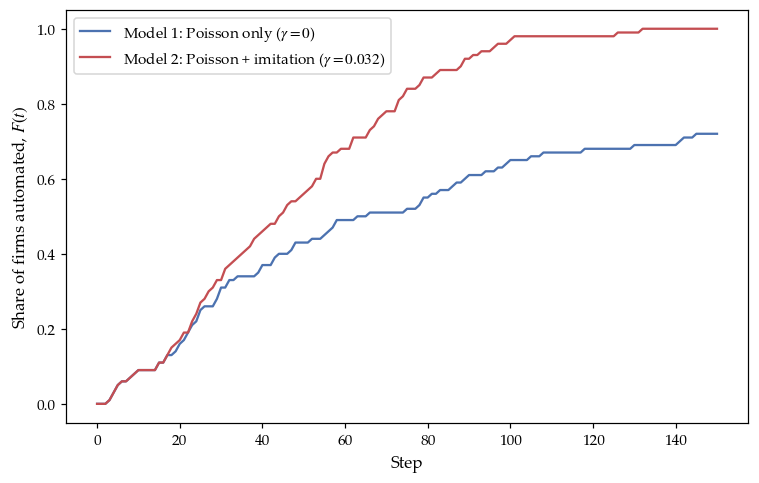

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(df1.index, df1["Firms_Automated"] / len(m1.firms_pool),
        label=r"Model 1: Poisson only ($\gamma=0$)", color="#4C72B0")
ax.plot(df2.index, df2["Firms_Automated"] / len(m2.firms_pool),
        label=r"Model 2: Poisson + imitation ($\gamma=0.032$)", color="#C44E52")
ax.set_xlabel("Step")
ax.set_ylabel("Share of firms automated, $F(t)$") # F(t) is the share of firms that have adopted AI automation at time t
ax.legend()
plt.tight_layout()
plt.show()


### Polarization index

The following code block visualizes the time series of the polarization index, computed as the ratio between the mean savings of Senior workers and Junior workers. The plot overlays the trajectories of all three specifications against a structural benchmark:

* **Baseline Scenario (control / `df0`):** Remains rigid at the horizontal reference line of 1.0, empirically confirming identical wealth accumulation between cohorts when automation is absent.
* **Model 1 (`gamma = 0` / `df1`):** Tracks the divergence in savings when displacement occurs independently of market state, driving the index above the 1.0 equilibrium floor.
* **Model 2 (`gamma = 0.032` / `df2`):** Captures the trajectory of the index under endogenously accelerated adoption, reflecting the impact of temporally clustered layoffs on the inter-cohort savings gap.

A ratio of 1.0 indicates no gap; departures from 1.0 reflect the compounding effect of differential exposure and, in Model 2,imitation-driven adoption speed.

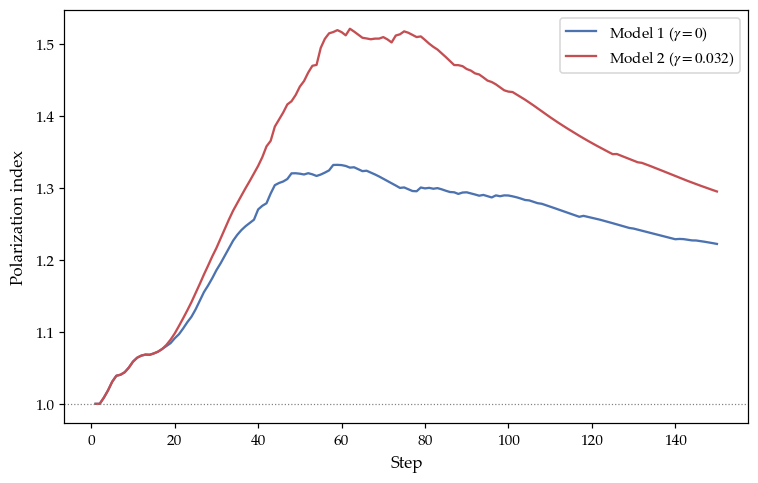

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(df1.index, df1["Polarization"], label=r"Model 1 ($\gamma=0$)", color="#4C72B0")
ax.plot(df2.index, df2["Polarization"], label=r"Model 2 ($\gamma=0.032$)", color="#C44E52")
ax.axhline(1.0, color="grey", linewidth=0.8, linestyle=":")
ax.set_xlabel("Step")
ax.set_ylabel("Polarization index")
ax.legend()
plt.tight_layout()
plt.show()

### Gini coefficient

The following code block plots the evolution of the aggregate Gini coefficient over worker savings to compare overall inequality across the three runs:

* **Baseline Scenario (control / `df0`):** Remains at 0.0, indicating perfect wealth equality when no automation shocks occur.
* **Model 1 (`gamma = 0` / `df1`):** Shows the steady rise in overall inequality caused by independent, exogenous AI adoptions and subsequent worker layoffs.
* **Model 2 (`gamma = 0.032` / `df2`):** Tracks the trajectory of inequality when adoptions accelerate over time due to imitation and social pressure.

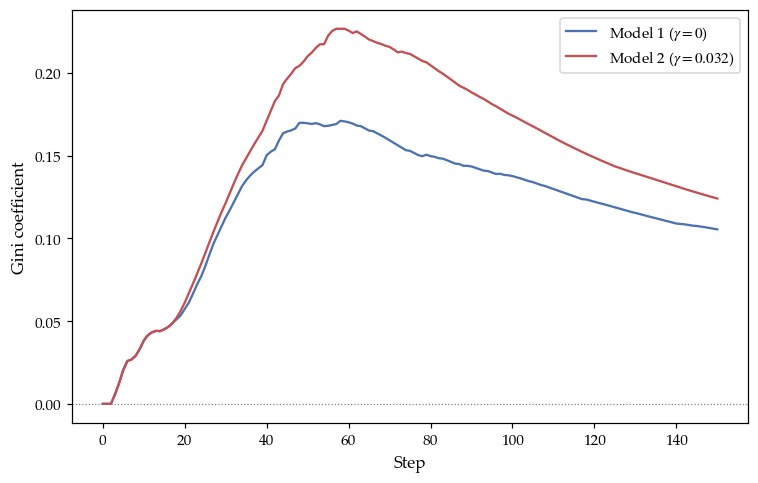

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(df1.index, df1["Gini"], label=r"Model 1 ($\gamma=0$)", color="#4C72B0")
ax.plot(df2.index, df2["Gini"], label=r"Model 2 ($\gamma=0.032$)", color="#C44E52")
ax.axhline(0.0, color="grey", linewidth=0.8, linestyle=":")
ax.set_xlabel("Step")
ax.set_ylabel("Gini coefficient")
ax.legend()
plt.tight_layout()
plt.show()


### Cumulative displacement and reskilling

The following code block plots the cumulative number of displaced workers against the total number of workers who successfully completed retraining under both models:

* **Model 1 ($\gamma = 0$ / `df1`):** Tracks displacement and retraining under independent, constant-hazard AI adoptions.
* **Model 2 ($\gamma = 0.032$ / `df2`):** Tracks displacement and retraining under accelerated adoptions driven by market imitation.

The baseline has no displacement mechanism and is excluded from this panel. `N_Reskilled_AmongDisplaced` is the subset that completed retraining. The gap between the two lines identifies workers re-entering employment without retraining, at the underemployment wage penalty.

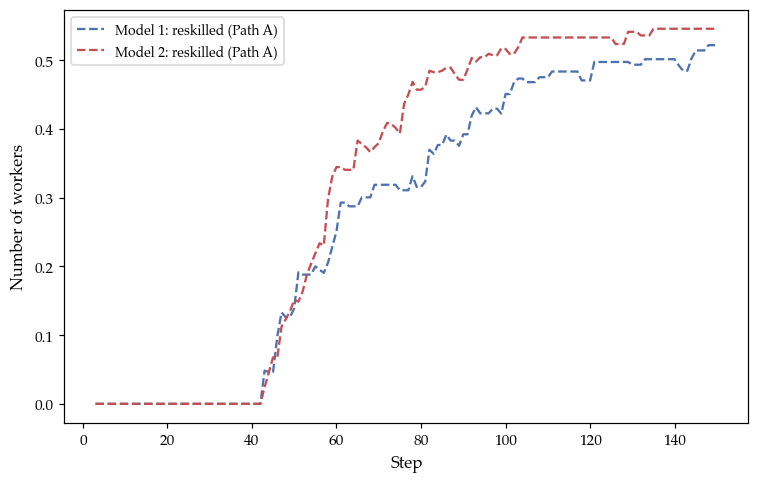

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(df1.index, df1["N_Reskilled_AmongDisplaced"], label="Model 1: reskilled (Path A)", color="#4C72B0", linestyle="--")
ax.plot(df2.index, df2["N_Reskilled_AmongDisplaced"], label="Model 2: reskilled (Path A)", color="#C44E52", linestyle="--")
ax.set_xlabel("Step")
ax.set_ylabel("Number of workers")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


### Within-cohort inequality among Juniors

The following code block plots the Gini coefficient calculated exclusively on the savings of Junior workers to compare within-cohort inequality across the three runs:

* **Baseline Scenario (control / `df0`):** Remains at 0.0, indicating perfect wealth equality within the Junior cohort in the absence of automation.
* **Model 1 ($\gamma = 0$ / `df1`):** Tracks the steady rise in intra-cohort inequality driven by independent, exogenous displacement.
* **Model 2 ($\gamma = 0.032$ / `df2`):** Tracks intra-cohort inequality under endogenously accelerated adoptions driven by market imitation.

The Gini coefficient computed over Junior workers' savings only, net of the Senior/Junior gap already captured above, isolating inequality generated within the high-exposure cohort.

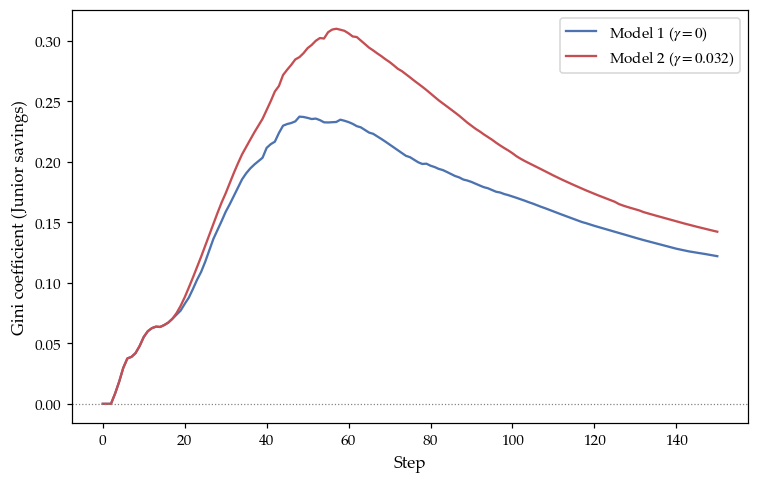

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(df1.index, df1["Gini_Savings_Junior"], label=r"Model 1 ($\gamma=0$)", color="#4C72B0")
ax.plot(df2.index, df2["Gini_Savings_Junior"], label=r"Model 2 ($\gamma=0.032$)", color="#C44E52")
ax.axhline(0.0, color="grey", linewidth=0.8, linestyle=":")
ax.set_xlabel("Step")
ax.set_ylabel("Gini coefficient (Junior savings)")
ax.legend()
plt.tight_layout()
plt.show()
